#Definição do Problema de Negócio
##Definição
Com o crescimento do comércio eletrônico, as avaliações publicadas pelos consumidores tornaram-se uma importante fonte de informação para compreender a percepção sobre produtos e serviços. Entretanto, o grande volume de comentários dificulta a análise manual e a identificação rápida de experiências negativas e oportunidades de melhoria.

Nesse cenário, técnicas de Processamento de Linguagem Natural (PLN) e Machine Learning podem ser utilizadas para automatizar a interpretação dos comentários, identificando padrões de opinião e classificando automaticamente o sentimento expresso pelos consumidores.

Para o desenvolvimento deste projeto, foi utilizado um conjunto de dados público disponibilizado na plataforma Kaggle, contendo avaliações textuais destinadas à análise de sentimentos. A partir dessas informações, foi proposta a construção de um modelo de classificação capaz de identificar automaticamente avaliações positivas e negativas.

##Objetivo

Desenvolver um modelo de Machine Learning capaz de analisar textos de avaliações de consumidores e classificá-los automaticamente em duas categorias: positivo ou negativo, permitindo identificar a percepção geral dos clientes em relação aos produtos avaliados.

##Benefícios Esperados
**Automatização da Análise:** Reduzir a necessidade de avaliação manual dos comentários, tornando o processamento de grandes volumes de feedback mais eficiente.

**Monitoramento da Satisfação:** Identificar padrões de avaliações positivas e negativas, oferecendo indicadores sobre a percepção dos consumidores.

**Identificação de Oportunidades de Melhoria:** Detectar insatisfações recorrentes e possíveis problemas relacionados aos produtos, contribuindo para decisões mais assertivas.

**Apoio à Tomada de Decisão:** Disponibilizar informações estruturadas para apoiar as equipes de produto, marketing e relacionamento com o cliente na definição de estratégias.

#Importação dos pacotes

In [1]:
# Manipulação de dados e visualização
import re
import pandas as pd
import numpy as np
import unicodedata
import seaborn as sns
import matplotlib.pyplot as plt

# Pré-Processamento e MachineLearning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import joblib
import statistics as sts
from sklearn.linear_model import LogisticRegression

# Carregando e Compreendendo os dados

In [2]:
# Define o nome do arquivo
dados = pd.read_csv("/content/selectedPreds.csv")

In [3]:
dados.shape

(863, 4)

In [4]:
#Amostra dos dados
dados.sample(10)

,DateNew,Tweet,Predicted,Positive_Prob
629,2019-11-29,cadê o picpay dando 50 reais de cashback nessa...,Negativo,0.097306
715,2019-12-01,eu que lute pra pagar a fatura do cartão dps d...,Negativo,0.099746
604,2019-11-29,Único black friday que eu vi valer a pena foi ...,Positivo,0.939281
97,2019-11-28,O bagulho já tá encerrado mano que merda é ess...,Negativo,0.089677
311,2019-11-28,Amanhã é dia de Black Friday no Manaira Shoppi...,Negativo,0.074215
795,2019-12-01,na black friday a loja tava cobrando quase 500...,Negativo,0.057536
441,2019-11-29,Amei minha compra de black friday um belisssim...,Positivo,0.937485
128,2019-11-28,"Black Friday horrível, o site não me deixou fi...",Negativo,0.038842
462,2019-11-29,queria ter dinheiro pra gastar horrores na bla...,Negativo,0.080599
332,2019-11-28,De que adianta Black Friday se eu não tenho di...,Negativo,0.027002


# Análise Exploratória de Dados (EDA)

Nesta etapa, investigamos o conjunto de dados para identificar padrões, tendências, possíveis inconsistências e características relevantes das informações. Por meio de visualizações gráficas e análises estatísticas, buscamos compreender a distribuição das classes, a frequência dos termos presentes nos textos e o comportamento geral das variáveis, estabelecendo uma base para as etapas seguintes do desenvolvimento do modelo de Machine Learning.

In [5]:
#Info
dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 863 entries, 0 to 862
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   DateNew        863 non-null    object 
 1   Tweet          863 non-null    object 
 2   Predicted      863 non-null    object 
 3   Positive_Prob  863 non-null    float64
dtypes: float64(1), object(3)
memory usage: 27.1+ KB


In [6]:
print("\n Verificando valores ausentes: \n")
print(dados.isnull().sum())


 Verificando valores ausentes: 

DateNew          0
Tweet            0
Predicted        0
Positive_Prob    0
dtype: int64



 Distribuição dos Sentimentos: 



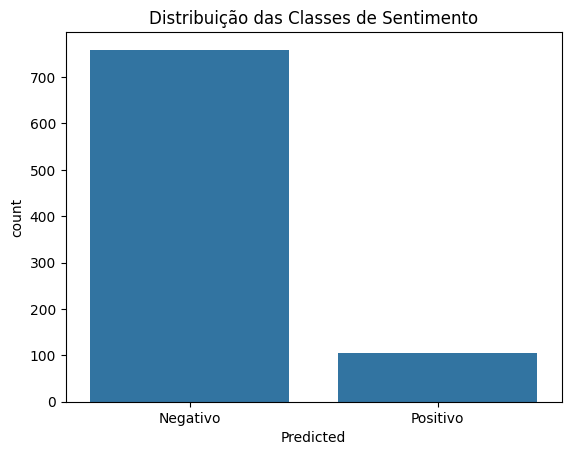

In [11]:
print("\n Distribuição dos Sentimentos: \n")
sns.countplot(x = "Predicted", data = dados)
plt.title("Distribuição das Classes de Sentimento")
plt.show()

# Limpeza de dados

Nessa etapa corrigimos os problemas identificados na EDA.

In [12]:
#Redefinindo colunas

def transformed_df(dados):
  dados = dados.rename(columns = {
      "DateNew": "Data",
      "Predicted": "Sentimento",
      "Positive_Prob": "Probabilidade_positivo"
  })
  return dados

In [13]:
dados = transformed_df(dados)
dados.head()

,Data,Tweet,Sentimento,Probabilidade_positivo
0,2019-11-28,querendo comprar umas coisas nessa black frida...,Negativo,0.078476
1,2019-11-28,Foda Black Friday no final do mês. Tenho dinhe...,Negativo,0.038238
2,2019-11-28,Vendo #ShowDaBlackFriday mesmo sem um tustão f...,Negativo,0.093840
3,2019-11-28,minha mãe sendo enganada caindo no conto da Bl...,Negativo,0.078509
4,2019-11-28,pra que black friday se eu não tenho dinheiro ...,Negativo,0.078804


In [14]:
dados[dados["Tweet"].duplicated(keep=False)]

,Data,Tweet,Sentimento,Probabilidade_positivo


In [15]:
# Função de Limpesa de texto

def limpa_tudo(texto):

    """
    Função completa de limpeza de texto:
    1. Converte para minúsculas.
    2. Remove acentos e cedilha.
    3. Remove pontuações, números e caracteres especiais.
    4. Remove espaços extras.
    """

    # Garante que o texto não seja nulo (caso haja algum NaN no DataFrame)
    if not isinstance(texto, str):
        return ""

    # --- PASSO 1: Normalizar e remover acentos ---
    # Normaliza para a forma 'NFKD' que separa o caractere da acentuação
    # e depois remove os acentos (Nonspacing Mark)
    texto_sem_acentos = ''.join(c for c in unicodedata.normalize('NFKD', texto) if unicodedata.category(c) != 'Mn')

    # --- PASSO 2: Limpeza com Regex ---
    # Converter para minúsculas
    texto_limpo = texto_sem_acentos.lower()

    # Manter apenas letras e espaços.  Aremoção de acentos já foi feita.
    texto_limpo = re.sub(r'[^a-z\s]', '', texto_limpo)

    # Remover espaços extras
    texto_limpo = re.sub(r'\s+', ' ', texto_limpo).strip()

    return texto_limpo

In [16]:
# Aplica a função de limpeza
dados['Texto_limpo'] = dados['Tweet'].apply(limpa_tudo)

In [17]:
dados.head()

,Data,Tweet,Sentimento,Probabilidade_positivo,Texto_limpo
0,2019-11-28,querendo comprar umas coisas nessa black frida...,Negativo,0.078476,querendo comprar umas coisas nessa black frida...
1,2019-11-28,Foda Black Friday no final do mês. Tenho dinhe...,Negativo,0.038238,foda black friday no final do mes tenho dinhei...
2,2019-11-28,Vendo #ShowDaBlackFriday mesmo sem um tustão f...,Negativo,0.093840,vendo showdablackfriday mesmo sem um tustao fu...
3,2019-11-28,minha mãe sendo enganada caindo no conto da Bl...,Negativo,0.078509,minha mae sendo enganada caindo no conto da bl...
4,2019-11-28,pra que black friday se eu não tenho dinheiro ...,Negativo,0.078804,pra que black friday se eu nao tenho dinheiro ...


# Engenharia de Atributos

Nesta etapa, os dados passam por transformações para torná-los adequados ao treinamento do modelo. O processo envolve a limpeza e padronização dos textos, a criação de novos atributos e a conversão das categorias de sentimento em valores numéricos (1 e 2), permitindo que o algoritmo de Machine Learning interprete e processe as informações durante o aprendizado.


In [18]:
# Mapear o sentimento para valores numéricos (Engenharia de Atributos)
dados["Sentimento_label"] = dados["Sentimento"].map({"Positivo": 1, "Negativo": 2})

In [19]:
print("\n DataFrame após a limpeza e mapeamento: \n")
dados[["Texto_limpo", "Sentimento_label"]].head()


 DataFrame após a limpeza e mapeamento: 



,Texto_limpo,Sentimento_label
0,querendo comprar umas coisas nessa black frida...,2
1,foda black friday no final do mes tenho dinhei...,2
2,vendo showdablackfriday mesmo sem um tustao fu...,2
3,minha mae sendo enganada caindo no conto da bl...,2
4,pra que black friday se eu nao tenho dinheiro ...,2


# Divisão em Dados de Treino e Teste
Nesta etapa, dividimos o conjunto de dados em dois subconjuntos: treinamento e teste. A primeira parcela é utilizada pelo algoritmo para identificar padrões e aprender as características dos dados, enquanto a segunda permanece separada durante o treinamento, sendo utilizada posteriormente para avaliar o desempenho do modelo diante de informações ainda não apresentadas.

In [20]:
#Definir variáveis de entrada x(entrada) e y(saída)
x = dados["Texto_limpo"]
y = dados["Sentimento_label"]

In [21]:
#Dividir os dados em treino e teste
x_treino, x_teste, y_treino,y_teste = train_test_split(x, y, test_size = 0.25, random_state = 42, stratify = y)

# Pipeline de modelagem preditiva

Nesta etapa, estruturamos um fluxo automatizado de processamento e classificação dos dados utilizando o Pipeline do Scikit-learn. A estrutura integra as etapas de pré-processamento textual, vetorização TF-IDF e treinamento do modelo de Regressão Logística, garantindo a padronização das operações e a aplicação consistente das mesmas transformações tanto nos dados de treinamento quanto em novas amostras.

In [22]:
# Pipiline
pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(stop_words = ['de', 'a', 'o', 'que', 'e', 'do', 'da', 'em', 'um'])), #Tudo que é texto vai virar número, exceto o que está listado em aspas
    ('scaler', StandardScaler(with_mean = False)),# Padronização dados passados para o algorítimo na mesma escala
    ('logreg', LogisticRegression(solver = 'liblinear', random_state = 42, max_iter = 1000))  #(hiperparâmetros)
])

#Vetorização dos Dados de Texto ('tfidf', TfidfVectorizer(...))
Converte os textos em representações numéricas por meio do TfidfVectorizer, atribuindo pesos às palavras conforme sua relevância em cada documento. Termos muito frequentes e pouco informativos podem ser desconsiderados por meio da remoção de stop words.

# Padronização de Dados ('scaler', StandardScaler(with_mean=False))
Ajusta a escala dos valores numéricos gerados na vetorização, contribuindo para a consistência do processamento. O parâmetro with_mean=False preserva a estrutura esparsa da matriz TF-IDF, evitando a conversão desnecessária de zeros e o aumento do consumo de memória.

# Modelo de Machine Learning ('logreg', LogisticRegression(...))
Utiliza os atributos numéricos processados para aprender padrões associados às classes de sentimento e realizar a classificação dos textos em positivos ou negativos..

A integração dessas etapas automatiza o fluxo de processamento e garante que as mesmas transformações sejam aplicadas durante o treinamento e na classificação de novos textos, reduzindo inconsistências e facilitando a utilização do modelo em produção.

# Otimização de Hiperparâmetros

É o ajuste fino do modelo. Usando GridSearchCV, testamos sistematicamente  várias combinações de configurações (hiperparâmetros) para o pipeline, a fim de encontrar a combinação que resulta na melhor performance possível.

In [23]:
#Definir o grid de hiperparâmetros para otimização

parametros_grid = {
    'tfidf__max_features': [500, 1000, 2000],
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'logreg__C': [0.1, 1, 10],
    'logreg__penalty': ['l1', 'l2'],
    'logreg__max_iter': [5000, 6000]
}

In [24]:
#Configurar o GridSearchCV
grid_search = GridSearchCV(
    pipeline,                 #Pipeline com as etapas de pré-processamento e modelo
    parametros_grid,          #Dicionário com as combinações de hiperparâmetros a serem testadas
    cv = 5,                   #Número de divisões para validações cruzada (5-fold cross- validation)
    n_jobs = -1,              #Usa todos os núcelos disponíveis do processador
    scoring = 'accuracy',     #Métrica usada para avaliar o desempenho de cada combinação (Aqui, acurácia)
    verbose = 1               #Nível de detalhamento do output dirante a execução (1 exibe o progrsso básico)
)

A validação cruzada é uma técnica utilizada para avaliar a capacidade de generalização do modelo. O conjunto de dados é dividido em múltiplas partes (folds), alternando entre treinamento e validação em diferentes rodadas. Ao final, os resultados são consolidados para obter uma estimativa mais consistente do desempenho do modelo, reduzindo a dependência de uma única divisão dos dados e contribuindo para uma avaliação mais robusta.

# Treinamento do modelo

Nessa etapa, alimentamos o pipeline com os dados de treino. O GridSearchCV executa o processso de .fit(), onde o algorítimo aprende os padrões que conectam o texto dos reviews aos seus respectivos sentimentos.

In [25]:
print("\n Iniciando o treinamento do modelo com otimização de hiperparâmetros ...\n")
grid_search.fit(x_treino, y_treino)


 Iniciando o treinamento do modelo com otimização de hiperparâmetros ...

Fitting 5 folds for each of 72 candidates, totalling 360 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('tfidf',
                                        TfidfVectorizer(stop_words=['de', 'a',
                                                                    'o', 'que',
                                                                    'e', 'do',
                                                                    'da', 'em',
                                                                    'um'])),
                                       ('scaler',
                                        StandardScaler(with_mean=False)),
                                       ('logreg',
                                        LogisticRegression(max_iter=1000,
                                                           random_state=42,
                                                           solver='liblinear'))]),
             n_jobs=-1,
             param_grid={'logreg__C': [0.1, 1, 10],
                         'logreg__max_iter': [5000, 6000],
                         'logreg__penalty': ['l1', 'l2'],
                         'tfidf__max_features': [500, 1000, 2000],
                         'tfidf__ngram_range': [(1, 1), (1, 2)]},
             scoring='accuracy', verbose=1)

In [26]:
print("\n Melhores hiperparâmetros encontrados: \n")
print(grid_search.best_params_)


 Melhores hiperparâmetros encontrados: 

{'logreg__C': 10, 'logreg__max_iter': 5000, 'logreg__penalty': 'l1', 'tfidf__max_features': 2000, 'tfidf__ngram_range': (1, 1)}


In [27]:
#Obter o melhor modelo
melhor_modelo = grid_search.best_estimator_

In [28]:
type(melhor_modelo)

sklearn.pipeline.Pipeline

# Avaliação do Modelo e Interpretação de Métricas

Nesta etapa, avaliamos o desempenho do modelo utilizando o conjunto de teste, composto por dados que não participaram do treinamento. As previsões são comparadas aos valores reais por meio de métricas como acurácia, precisão, recall e F1-score, além da matriz de confusão. Esses indicadores permitem analisar a qualidade das classificações, identificar possíveis erros e verificar a capacidade de generalização do modelo em relação aos objetivos propostos.

In [29]:
# Previsões do conjunto de teste
y_pred= melhor_modelo.predict(x_teste)

In [30]:
#Calcular as métricas de avaliação
acuracia = accuracy_score(y_teste, y_pred)
report = classification_report(y_teste, y_pred, target_names = ['Negativo', 'Positivo'])

In [31]:
print(f"\n Acurácia do Modelo: {acuracia:.2%}\n")
print("Relatório de Classificação: \n")
print(report)


 Acurácia do Modelo: 94.91%

Relatório de Classificação: 

              precision    recall  f1-score   support

    Negativo       1.00      0.58      0.73        26
    Positivo       0.95      1.00      0.97       190

    accuracy                           0.95       216
   macro avg       0.97      0.79      0.85       216
weighted avg       0.95      0.95      0.94       216



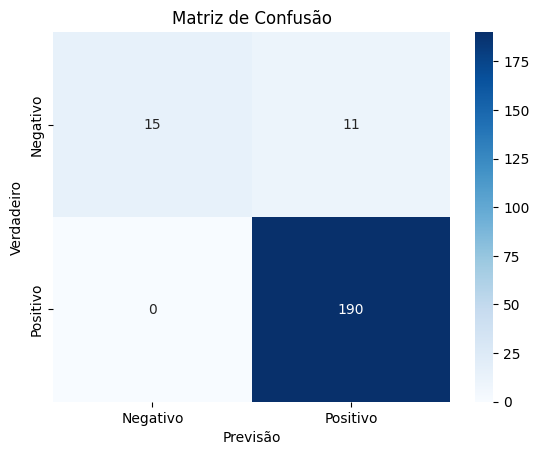

In [32]:
# Visualização da Matriz de Confusão
cm = confusion_matrix(y_teste, y_pred)
sns.heatmap(cm, annot = True, fmt = 'd', cmap = 'Blues',
            xticklabels = ['Negativo', 'Positivo'],
            yticklabels = ['Negativo', 'Positivo'])

plt.xlabel('Previsão')
plt.ylabel('Verdadeiro')
plt.title('Matriz de Confusão')
plt.show()

1. Acurácia (Accuracy)

De todos os reviews (positivos e negativos) que o modelo analisou, qual a porcentagem total de acertos?

No contexto acima: De 100 reviews pelo modelo e ele acertou a classificação de 95 deles (independentemente de serem positivos ou negativos), a acurácia é de 94.91%. É a medida mais geral de performance.

2. Precisão (Precision)

Esta métrica é calculada para cada classe.
- Negativo: 0,58 (58%) — o modelo conseguiu identificar corretamente apenas 58% das avaliações realmente negativas.
- Positivo: 1,00 (100%) — todas as avaliações realmente positivas foram identificadas corretamente.


3. Recall

Esta métrica também é calculada para cada classe.

Negativo: 0,73 (73%) — desempenho moderado na classificação dos sentimentos negativos.

Positivo: 0,97 (97%) — excelente equilíbrio entre precisão e recall na identificação dos sentimentos positivos.

O modelo apresenta desempenho significativamente superior na classificação de avaliações positivas.

O modelo apresentou excelente desempenho geral, especialmente na identificação de avaliações positivas. Entretanto, a sensibilidade de 58% para a classe negativa indica uma limitação importante na identificação desse tipo de sentimento.

In [33]:
# Salvamento do modelo em disco
joblib.dump(melhor_modelo, 'modelo_sentimento_v1.joblib')

['modelo_sentimento_v1.joblib']

## 10. MLOps, Deploy e Uso do Modelo

Nesta etapa, simulamos a disponibilização do modelo treinado para utilização em novas situações. Para isso, desenvolvemos a função que encapsula o pipeline de Machine Learning e permite classificar automaticamente novos textos como positivos ou negativos, sem a necessidade de repetir manualmente as etapas de pré-processamento.

Essa abordagem representa uma etapa inicial de implantação do modelo, demonstrando como a solução pode ser integrada a aplicações e processos automatizados. Também introduz conceitos de MLOps, relacionados à implantação, monitoramento, manutenção e atualização contínua de modelos de Machine Learning em ambientes de produção.

In [34]:
#Caregar o modelo a partir do disco
modelo_deploy = joblib.load('modelo_sentimento_v1.joblib')

In [35]:
type(modelo_deploy)

sklearn.pipeline.Pipeline

In [36]:
# Criar novos dados para simular o uso em produção
novos_reviews = [
    "O produto superou minhas expectativas, excelente qualidade e acabamento.",
    "A entrega atrasou bastante e o produto chegou danificado.",
    "Gostei muito da experiência, atendimento atencioso e compra fácil.",
    "Produto de baixa qualidade, não funciona corretamente e me decepcionou."
]

In [37]:
# Função para prever o sentimento de novos reviews
def prever_sentimento(reviews):

    """
    Recebe uma lista de textos de review e retorna a previsão de sentimento.
    O objeto 'melhor_modelo_dsa' (pipeline) cuida de todos os passos internos.
    """

    # 1. 'reviews' entra no pipeline
    # 2. TF-IDF é aplicado internamente
    # 3. StandardScaler é aplicado internamente
    # 4. LogisticRegression faz a previsão
    previsoes = modelo_deploy.predict(reviews)

    # Mapeia o resultado numérico de volta para texto
    sentimentos = ['Negativo' if p == 0 else 'Positivo' for p in previsoes]

    # Exibe os resultados
    for review, sentimento in zip(reviews, sentimentos):
        print(f"\nReview: '{review}'\nSentimento Previsto: {sentimento}\n---")

In [38]:
# Executar a função de deploy com os novos dados
print("\n--- Iniciando Classificação de Novos Reviews (Deploy com Pipeline Completo) ---\n")
prever_sentimento(novos_reviews)


--- Iniciando Classificação de Novos Reviews (Deploy com Pipeline Completo) ---


Review: 'O produto superou minhas expectativas, excelente qualidade e acabamento.'
Sentimento Previsto: Positivo
---

Review: 'A entrega atrasou bastante e o produto chegou danificado.'
Sentimento Previsto: Positivo
---

Review: 'Gostei muito da experiência, atendimento atencioso e compra fácil.'
Sentimento Previsto: Positivo
---

Review: 'Produto de baixa qualidade, não funciona corretamente e me decepcionou.'
Sentimento Previsto: Positivo
---


# Conclusão

O desenvolvimento deste projeto permitiu explorar, na prática, as principais etapas de construção de uma solução de Machine Learning aplicada ao Processamento de Linguagem Natural (PLN), desde a investigação e preparação dos dados até o treinamento, otimização, avaliação e simulação da implantação do modelo.

A combinação da vetorização TF-IDF com o algoritmo de Regressão Logística apresentou um resultado inicial expressivo, alcançando 94,91% de acurácia no conjunto de teste. Entretanto, uma análise mais aprofundada das métricas revelou diferenças importantes entre as classes: enquanto o modelo apresentou excelente desempenho na identificação de sentimentos positivos, com recall de 100%, a identificação de avaliações negativas alcançou apenas 58%.

Essa limitação tornou-se ainda mais evidente durante a simulação de utilização em produção, quando novos reviews foram submetidos ao modelo. Apesar do bom desempenho observado na avaliação inicial, todas as novas amostras foram classificadas como positivas, inclusive aquelas com conteúdo claramente negativo.

Esse comportamento evidencia um dos desafios fundamentais do desenvolvimento de modelos preditivos: um bom resultado nas métricas de avaliação não garante, isoladamente, um desempenho satisfatório diante de novos dados. Aspectos como o desequilíbrio entre classes, a representatividade dos dados e a capacidade de generalização precisam ser considerados durante todo o ciclo de desenvolvimento.

Como oportunidades de evolução, destacam-se a aplicação de técnicas de balanceamento de classes, o aprimoramento da representação textual, a experimentação com diferentes algoritmos de classificação e a investigação de abordagens mais avançadas de Processamento de Linguagem Natural, incluindo modelos baseados em Transformers e LLMs.

Além do conhecimento técnico adquirido, o projeto reforçou a importância de uma abordagem analítica e crítica na construção de soluções inteligentes. Mais do que alcançar métricas elevadas, desenvolver Machine Learning significa compreender os dados, questionar os resultados, identificar limitações e aprimorar continuamente os modelos para gerar valor em aplicações reais.